# Imports and Installations

In [1]:
import pandas as pd
import requests
import time
from pybedtools import BedTool
import matplotlib.pyplot as plt
import pysam

# Get Chromosome, Start, and End for Each Gene

In [2]:
input_file = "../data/epigenetic_genes/all_epigenetic_genes.csv"
output_file = "../data/coordinate_data/gene_coordinates.csv"

gene_file = pd.read_csv(input_file)

hugo_symbols = gene_file["HugoSymbol"]

def get_coords(symbol, species="human", max_retries=5):
    url = f"https://rest.ensembl.org/lookup/symbol/{species}/{symbol}"
    headers = {"Content-Type": "application/json"}

    for attempt in range(max_retries):
        r = requests.get(url, headers=headers)

        if r.status_code == 200:
            d = r.json()
            return {
                "symbol": symbol,
                "chrom": d.get("seq_region_name"),
                "start": d.get("start"),
                "end": d.get("end"),
                "strand": d.get("strand"),
                "ensembl_id": d.get("id"),
                "status": "ok",
            }

        elif r.status_code == 429:
            wait = float(r.headers.get("Retry-After", 1))
            print(f"  rate limited on {symbol}, waiting {wait}s...")
            time.sleep(wait)
            continue  # retry, don't count against max_retries as a real failure

        elif r.status_code >= 500:
            wait = 2 ** attempt
            print(f"  server error ({r.status_code}) on {symbol}, retrying in {wait}s...")
            time.sleep(wait)
            continue

        elif r.status_code == 404:
            return {"symbol": symbol, "chrom": None, "start": None, "end": None, "status": "not_found"}

        else:
            return {"symbol": symbol, "chrom": None, "start": None, "end": None,
                     "status": f"error_{r.status_code}"}
        
    return {"symbol": symbol, "chrom": None, "start": None, "end": None, "status": "failed_after_retries"}

results = []
total = len(hugo_symbols)
n_ok, n_fail = 0, 0

for i, sym in enumerate(hugo_symbols, start=1):
    res = get_coords(sym)
    results.append(res)

    if res["chrom"] is not None:
        n_ok += 1
    else:
        n_fail += 1

    print(f"[{i}/{total}] {sym:<12} -> "
          f"{'OK' if res['chrom'] else 'NOT FOUND'}  "
          f"(ok={n_ok}, failed={n_fail})")

    time.sleep(0.1)

print(f"\nDone. {n_ok}/{total} resolved, {n_fail} failed.")

df = pd.DataFrame(results)
df.to_csv(output_file, index=False)


[1/549] ASH1L        -> OK  (ok=1, failed=0)
[2/549] ATAD2        -> OK  (ok=2, failed=0)
[3/549] ATAD2B       -> OK  (ok=3, failed=0)
  server error (503) on BAZ1A, retrying in 1s...
[4/549] BAZ1A        -> OK  (ok=4, failed=0)
  server error (500) on BAZ1B, retrying in 1s...
  server error (500) on BAZ1B, retrying in 2s...
  server error (500) on BAZ1B, retrying in 4s...
  server error (500) on BAZ1B, retrying in 8s...
[5/549] BAZ1B        -> OK  (ok=5, failed=0)
[6/549] BAZ2A        -> OK  (ok=6, failed=0)
[7/549] BAZ2B        -> OK  (ok=7, failed=0)
[8/549] BPTF         -> OK  (ok=8, failed=0)
[9/549] BRD1         -> OK  (ok=9, failed=0)
[10/549] BRD2         -> OK  (ok=10, failed=0)
[11/549] BRD3         -> OK  (ok=11, failed=0)
[12/549] BRD4         -> OK  (ok=12, failed=0)
[13/549] BRD7         -> OK  (ok=13, failed=0)
[14/549] BRD8         -> OK  (ok=14, failed=0)
[15/549] BRD9         -> OK  (ok=15, failed=0)
[16/549] BRDT         -> OK  (ok=16, failed=0)
[17/549] BRPF1       

# Remove Genes on Chromosome X or Y

In [3]:
file = "../data/coordinate_data/gene_coordinates.csv"

df = pd.read_csv(file)

df = df[df["chrom"] != 'X']
df = df[df["chrom"] != 'Y']

df.to_csv(file, index=False)

# Convert CSV to BED File

In [4]:
input_file = "../data/coordinate_data/gene_coordinates.csv"
output_file = "../data/coordinate_data/coordinates.bed"

df = pd.read_csv(input_file, header=0)

df['chrom'] = 'chr' + df['chrom'].astype(str)
df['strand'] = df['strand'].map({1: '+', -1: '-'})

bed_df = pd.DataFrame({
    'chrom': df['chrom'],
    'start': df['start'],
    'end': df['end'],
    'name': df['symbol'],     
    'score': df['ensembl_id'],  
    'strand': df['strand']       
})

bed_df.to_csv(output_file, sep='\t', header=False, index=False)

# Expand Gene Region

In [5]:
input_file = "../data/coordinate_data/coordinates.bed"
genome_file = "../data/reference_data/human.hg38.genome"
output_file = "../data/coordinate_data/final_gene_coordinates.bed"

bed_file = BedTool(input_file)

bed_file_expanded = bed_file.slop(b=100000, g=str(genome_file), output=output_file)

# Split Samples by Population

In [6]:
%%bash

for pop in YRI LWK GWD MSL ESN ASW ACB; do
    tail -n +2 ../data/reference_data/igsr_samples.tsv | awk -F'\t' -v p="$pop" '
    {
        n = split($4, codes, ",")
        for (i=1; i<=n; i++) {
            if (codes[i] == p) { print $1; break }
        }
    }' > ../data/population_data/${pop}/${pop}_samples.txt
    echo "$pop: $(wc -l < ../data/population_data/${pop}/${pop}_samples.txt) samples"
done

YRI:      178 samples
LWK:       99 samples


GWD:      178 samples
MSL:      100 samples
ESN:      149 samples
ASW:       74 samples
ACB:      116 samples


# Get Epigenetic Genes from 1000 Genomes Data

In [7]:
%%bash

for chr in {1..22}; do
    bcftools view -R ../data/coordinate_data/final_gene_coordinates.bed ../data/1000_genomes_data/subset_chr${chr}.vcf.gz -Oz -o ../data/gene_data/epi_chr${chr}.vcf.gz
    bcftools index ../data/gene_data/epi_chr${chr}.vcf.gz
done

# Concatenate Genes into One File

In [8]:
%%bash

bcftools concat ../data/gene_data/epi_chr{1..22}.vcf.gz -Oz -o ../data/gene_data/epi_allchr.vcf.gz
bcftools index ../data/gene_data/epi_allchr.vcf.gz

Checking the headers and starting positions of 22 files


Concatenating ../data/gene_data/epi_chr1.vcf.gz	10.436328 seconds
Concatenating ../data/gene_data/epi_chr2.vcf.gz	8.723410 seconds
Concatenating ../data/gene_data/epi_chr3.vcf.gz	6.017163 seconds
Concatenating ../data/gene_data/epi_chr4.vcf.gz	3.670325 seconds
Concatenating ../data/gene_data/epi_chr5.vcf.gz	4.532014 seconds
Concatenating ../data/gene_data/epi_chr6.vcf.gz	6.858792 seconds
Concatenating ../data/gene_data/epi_chr7.vcf.gz	5.274001 seconds
Concatenating ../data/gene_data/epi_chr8.vcf.gz	2.527852 seconds
Concatenating ../data/gene_data/epi_chr9.vcf.gz	5.573125 seconds
Concatenating ../data/gene_data/epi_chr10.vcf.gz	2.747047 seconds
Concatenating ../data/gene_data/epi_chr11.vcf.gz	6.872207 seconds
Concatenating ../data/gene_data/epi_chr12.vcf.gz	8.370855 seconds
Concatenating ../data/gene_data/epi_chr13.vcf.gz	1.929792 seconds
Concatenating ../data/gene_data/epi_chr14.vcf.gz	4.060062 seconds
Concatenating ../data/gene_data/epi_chr15.vcf.gz	0.159651 seconds
Concatenating ../d

# Filter Variants by Frequency

In [9]:
%%bash

bcftools view -m2 -M2 -v snps ../data/gene_data/epi_allchr.vcf.gz -Oz -o ../data/gene_data/epi_biallelic.vcf.gz

bcftools filter -i 'AF >= 0.05' ../data/gene_data/epi_biallelic.vcf.gz -Oz -o ../data/population_visualisation/epi_highfreq.vcf.gz
bcftools index ../data/population_visualisation/epi_highfreq.vcf.gz

for pop in YRI LWK GWD MSL ESN ASW ACB; do
    bcftools view -S ../data/population_data/${pop}/${pop}_samples.txt ../data/population_visualisation/epi_highfreq.vcf.gz -Oz -o ../data/population_data/${pop}/${pop}_epi_highfreq.vcf.gz
    bcftools index ../data/population_data/${pop}/${pop}_epi_highfreq.vcf.gz
done

### Plot Top 20 Genes by Total Variants

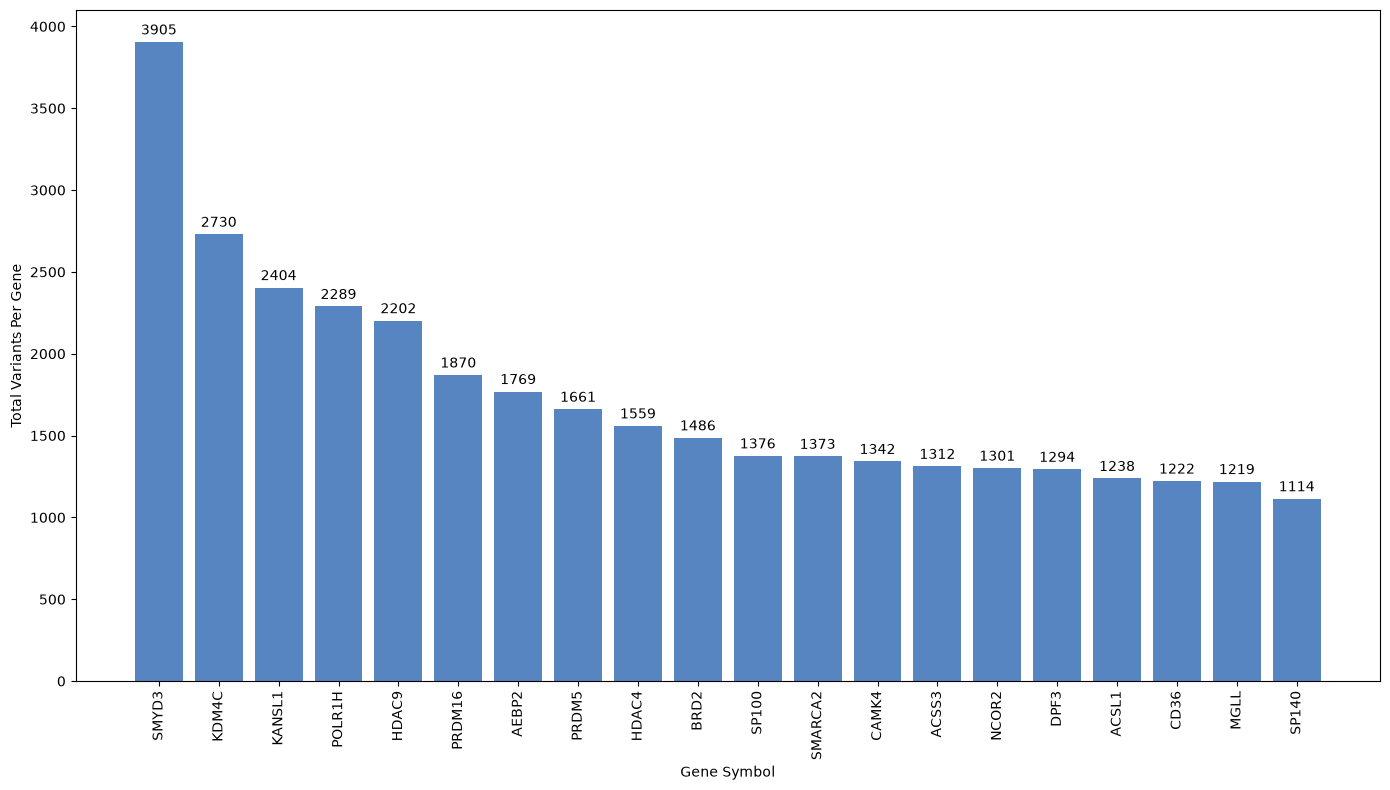

In [10]:
gene_df = pd.read_csv(
    bed_file_expanded.fn,
    sep="\t",
    header=None,
    names=["chrom", "start", "end", "name", "score", "strand"]
)

gene_df["chrom"] = gene_df["chrom"].str.replace("chr", "", regex=False)

vcf_path = "../data/population_visualisation/epi_highfreq.vcf.gz"

counts = {}

vcf = pysam.VariantFile(vcf_path)
for rec in vcf:
    chrom = rec.chrom.replace("chr", "")
    pos = rec.pos

    matches = gene_df[
        (gene_df["chrom"] == chrom) &
        (gene_df["start"] <= pos) &
        (gene_df["end"] >= pos)
    ]

    for gene_name in matches["name"].unique():
        counts[gene_name] = counts.get(gene_name, 0) + 1

counts_df = pd.DataFrame(
    {"gene": counts.keys(), "n_variants": counts.values()}
).sort_values("n_variants", ascending=False)

top_n = 20
plot_df = counts_df.head(top_n)

plt.figure(figsize=(14, 8))
bars = plt.bar(plot_df["gene"], plot_df["n_variants"], color="#5785C1")
plt.bar_label(bars, padding=3)
plt.xticks(rotation=90)
plt.ylabel("Total Variants Per Gene")
plt.xlabel("Gene Symbol")
plt.tight_layout()
plt.savefig('../data/gene_data/variants_per_gene.png')
plt.show()